## One Courier's Workday Time Allocation (Flag 11)

### Dataset Overview

One continuous courier workday containing 17 delivery-location visits, task counts per visit, and timestamped GPS activity states. Road reconstruction: 1032 GPS points along the archived local OSM street network, with all road vertices retained and irregular moving intervals bounded by 45 m. Oneway tags are respected; turn-restriction relations are not modeled. Times are local Shanghai time; speed_kmh and activity_state describe the preceding segment. Task events and AOI locations are constructed, not authentic observations.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze the courier's workday time allocation, delivery-visit efficiency, and unusually long visits.

Role: Last-mile delivery operations analyst


Category: workday time allocation and delivery-visit efficiency


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_visits.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How is the observed workday divided between travel and time near delivery locations?

#### Analysis action

Calculate durations from consecutive trajectory states and compare their totals.

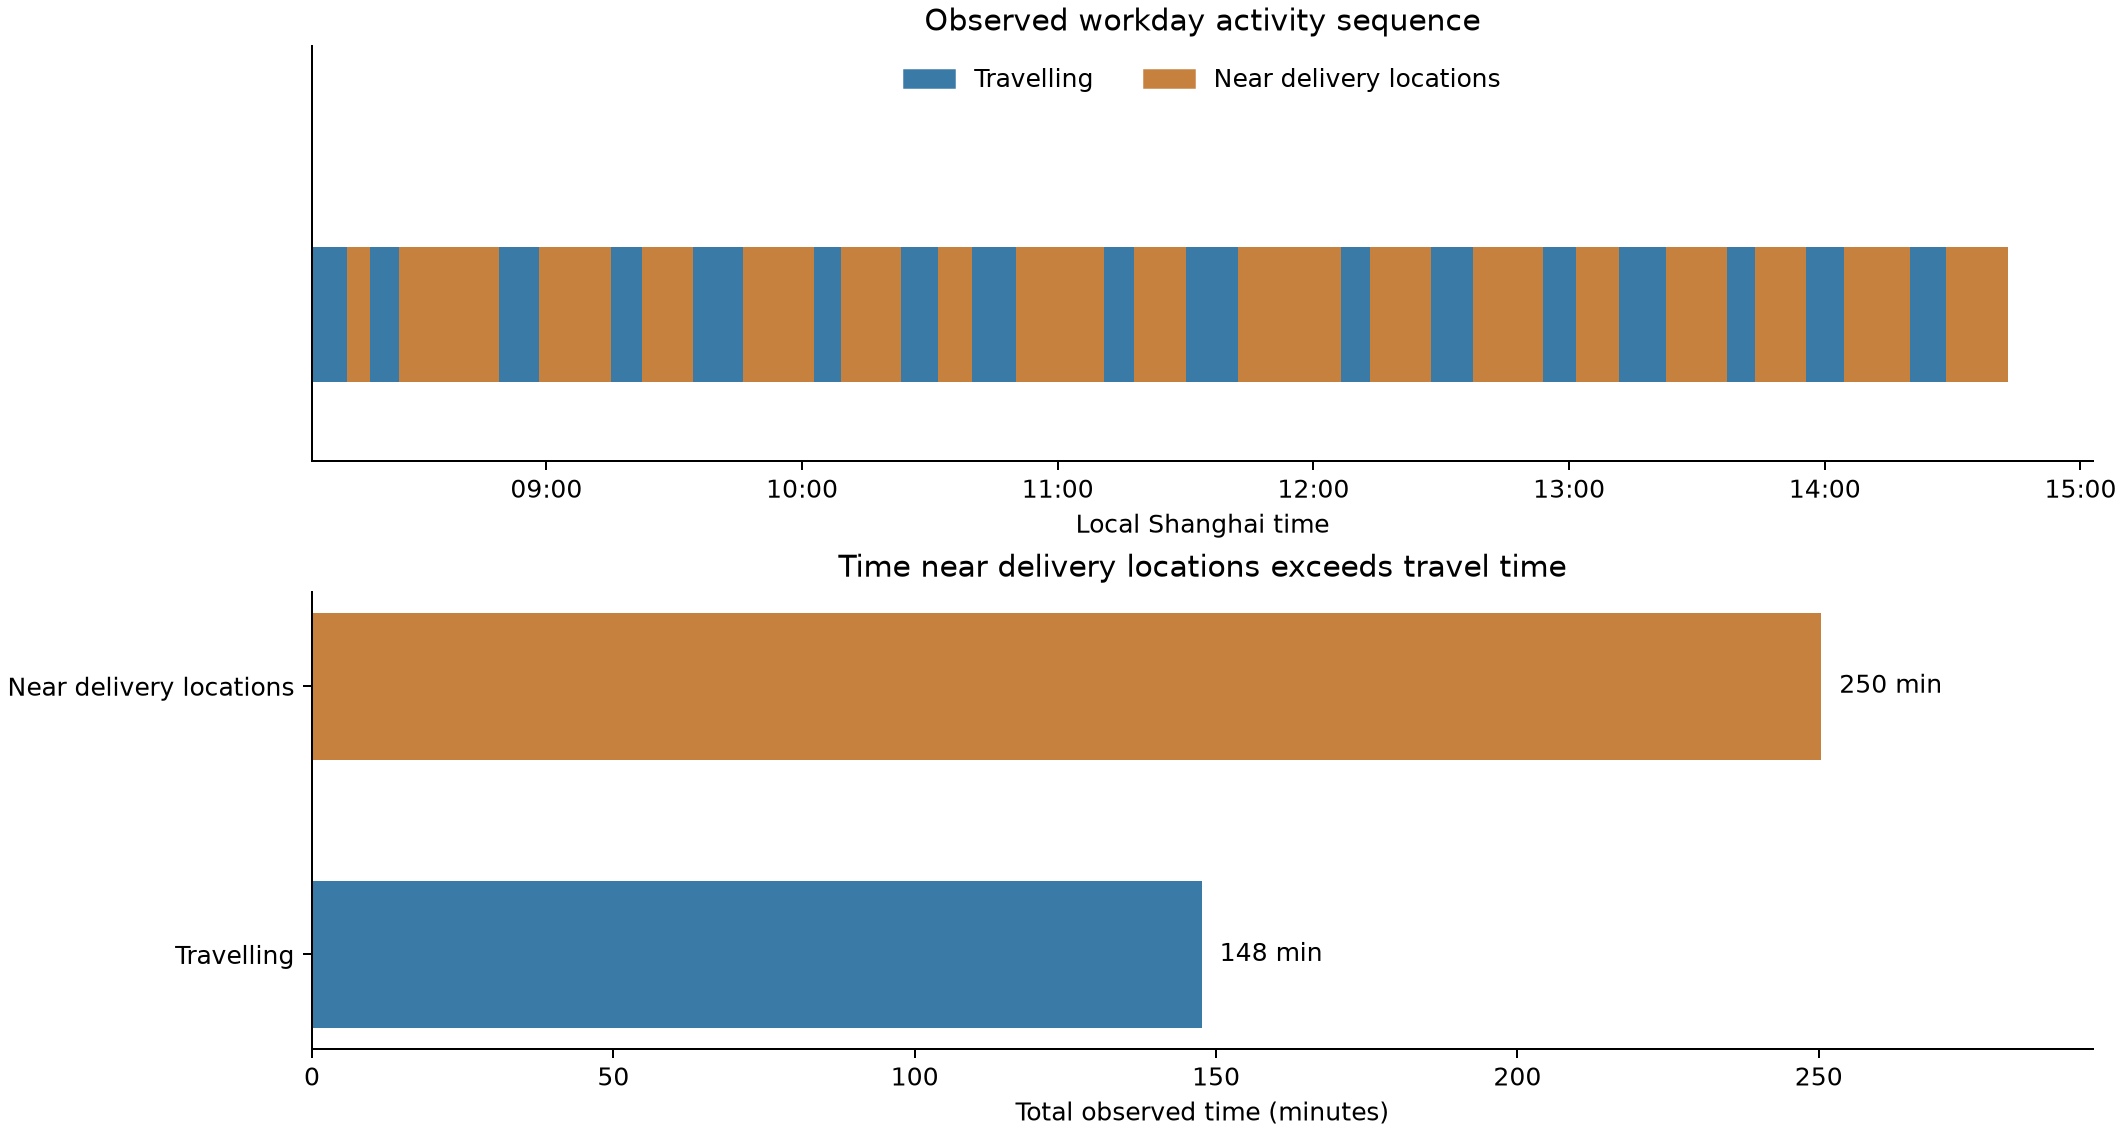

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


def allocation(df, user_df):
    import matplotlib.dates as mdates
    from matplotlib.patches import Patch

    q = user_df.sort_values("gps_time").copy()
    stamps = pd.to_datetime(q.gps_time, format="mixed")
    minutes = stamps.diff().dt.total_seconds() / 60
    totals = minutes.groupby(q.activity_state).sum()
    colors = {"travelling": "#397aa7", "near_delivery_location": "#c7813e"}
    fig, (timeline, total) = plt.subplots(
        2,
        1,
        figsize=(11.8, 6.3),
        constrained_layout=True,
        gridspec_kw={"height_ratios": [1, 1.1]},
    )
    # Each row's state describes its PRECEDING GPS interval.
    for i in range(1, len(q)):
        timeline.barh(
            0,
            mdates.date2num(stamps.iloc[i]) - mdates.date2num(stamps.iloc[i - 1]),
            left=mdates.date2num(stamps.iloc[i - 1]),
            height=0.55,
            color=colors[q.activity_state.iloc[i]],
            linewidth=0,
        )
    timeline.set(
        ylim=(-0.6, 1.1),
        yticks=[],
        xlabel="Local Shanghai time",
        title="Observed workday activity sequence",
    )
    timeline.xaxis_date()
    timeline.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    timeline.legend(
        handles=[
            Patch(color=colors["travelling"], label="Travelling"),
            Patch(
                color=colors["near_delivery_location"], label="Near delivery locations"
            ),
        ],
        loc="upper center",
        ncol=2,
        frameon=False,
    )
    values = [float(totals["travelling"]), float(totals["near_delivery_location"])]
    total.barh(
        ["Travelling", "Near delivery locations"],
        values,
        color=list(colors.values()),
        height=0.55,
    )
    for y, v in enumerate(values):
        total.text(v + 3, y, f"{v:.0f} min", va="center")
    total.set(
        xlim=(0, max(values) * 1.18),
        xlabel="Total observed time (minutes)",
        title="Time near delivery locations exceeds travel time",
    )
    for ax in [timeline, total]:
        ax.spines[["top", "right"]].set_visible(False)
    return {
        "travelling_minutes": round(values[0], 1),
        "near_delivery_minutes": round(values[1], 1),
    }


evidence = allocation(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/workday_time_allocation.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "workday_activity_timeline",
  "insight_type": "overall_pattern",
  "insight": "The courier spends more time near delivery locations than travelling between them.",
  "insight_value": {
    "near_delivery_minutes": 250.4,
    "travelling_minutes": 147.6
  },
  "plot": {
    "plot_type": "activity_timeline_and_time_totals",
    "title": "Workday Time Allocation",
    "file": "visualizations/workday_time_allocation.png",
    "description": "The complete activity timeline and totals compare time travelling with time spent near delivery locations."
  },
  "question": "How is the observed workday divided between travel and time near delivery locations?",
  "actionable_insight": "Calculate durations from consecutive trajectory states and compare their totals.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\ndef allocation(df, user_df):\n    import matplotlib.dates as mdates\n    from matplotlib.patches import Patch\n\n    q = user_df.sort_values('gps_time').copy()\n    stamps = pd.to_datetime(q.gps_time, format='mixed')\n    minutes = stamps.diff().dt.total_seconds()/60\n    totals = minutes.groupby(q.activity_state).sum()\n    colors = {'travelling': '#397aa7', 'near_delivery_location': '#c7813e'}\n    fig, (timeline, total) = plt.subplots(\n        2, 1, figsize=(11.8, 6.3), constrained_layout=True,\n        gridspec_kw={'height_ratios': [1, 1.1]})\n    # Each row's state describes its PRECEDING GPS interval.\n    for i in range(1, len(q)):\n        timeline.barh(0, mdates.date2num(stamps.iloc[i])-mdates.date2num(stamps.iloc[i-1]),\n            left=mdates.date2num(stamps.iloc[i-1]), height=.55,\n            color=colors[q.activity_state.iloc[i]], linewidth=0)\n    timeline.set(ylim=(-.6, 1.1), yticks=[], xlabel='Local Shanghai time',\n        title='Observed workday activity sequence')\n    timeline.xaxis_date()\n    timeline.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))\n    timeline.legend(handles=[Patch(color=colors['travelling'], label='Travelling'),\n        Patch(color=colors['near_delivery_location'], label='Near delivery locations')],\n        loc='upper center', ncol=2, frameon=False)\n    values = [float(totals['travelling']), float(totals['near_delivery_location'])]\n    total.barh(['Travelling', 'Near delivery locations'], values,\n        color=list(colors.values()), height=.55)\n    for y, v in enumerate(values): total.text(v+3, y, f'{v:.0f} min', va='center')\n    total.set(xlim=(0, max(values)*1.18), xlabel='Total observed time (minutes)',\n        title='Time near delivery locations exceeds travel time')\n    for ax in [timeline, total]:\n        ax.spines[['top', 'right']].set_visible(False)\n    return {'travelling_minutes': round(values[0], 1), 'near_delivery_minutes': round(values[1], 1)}\n\nevidence = allocation(df, user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_time",
    "gps_position"
  ]
}

### **Question 2**: How does time per completed delivery vary with the number completed during a visit?

#### Analysis action

Compare the full visit-level distributions and means by completed-delivery count.

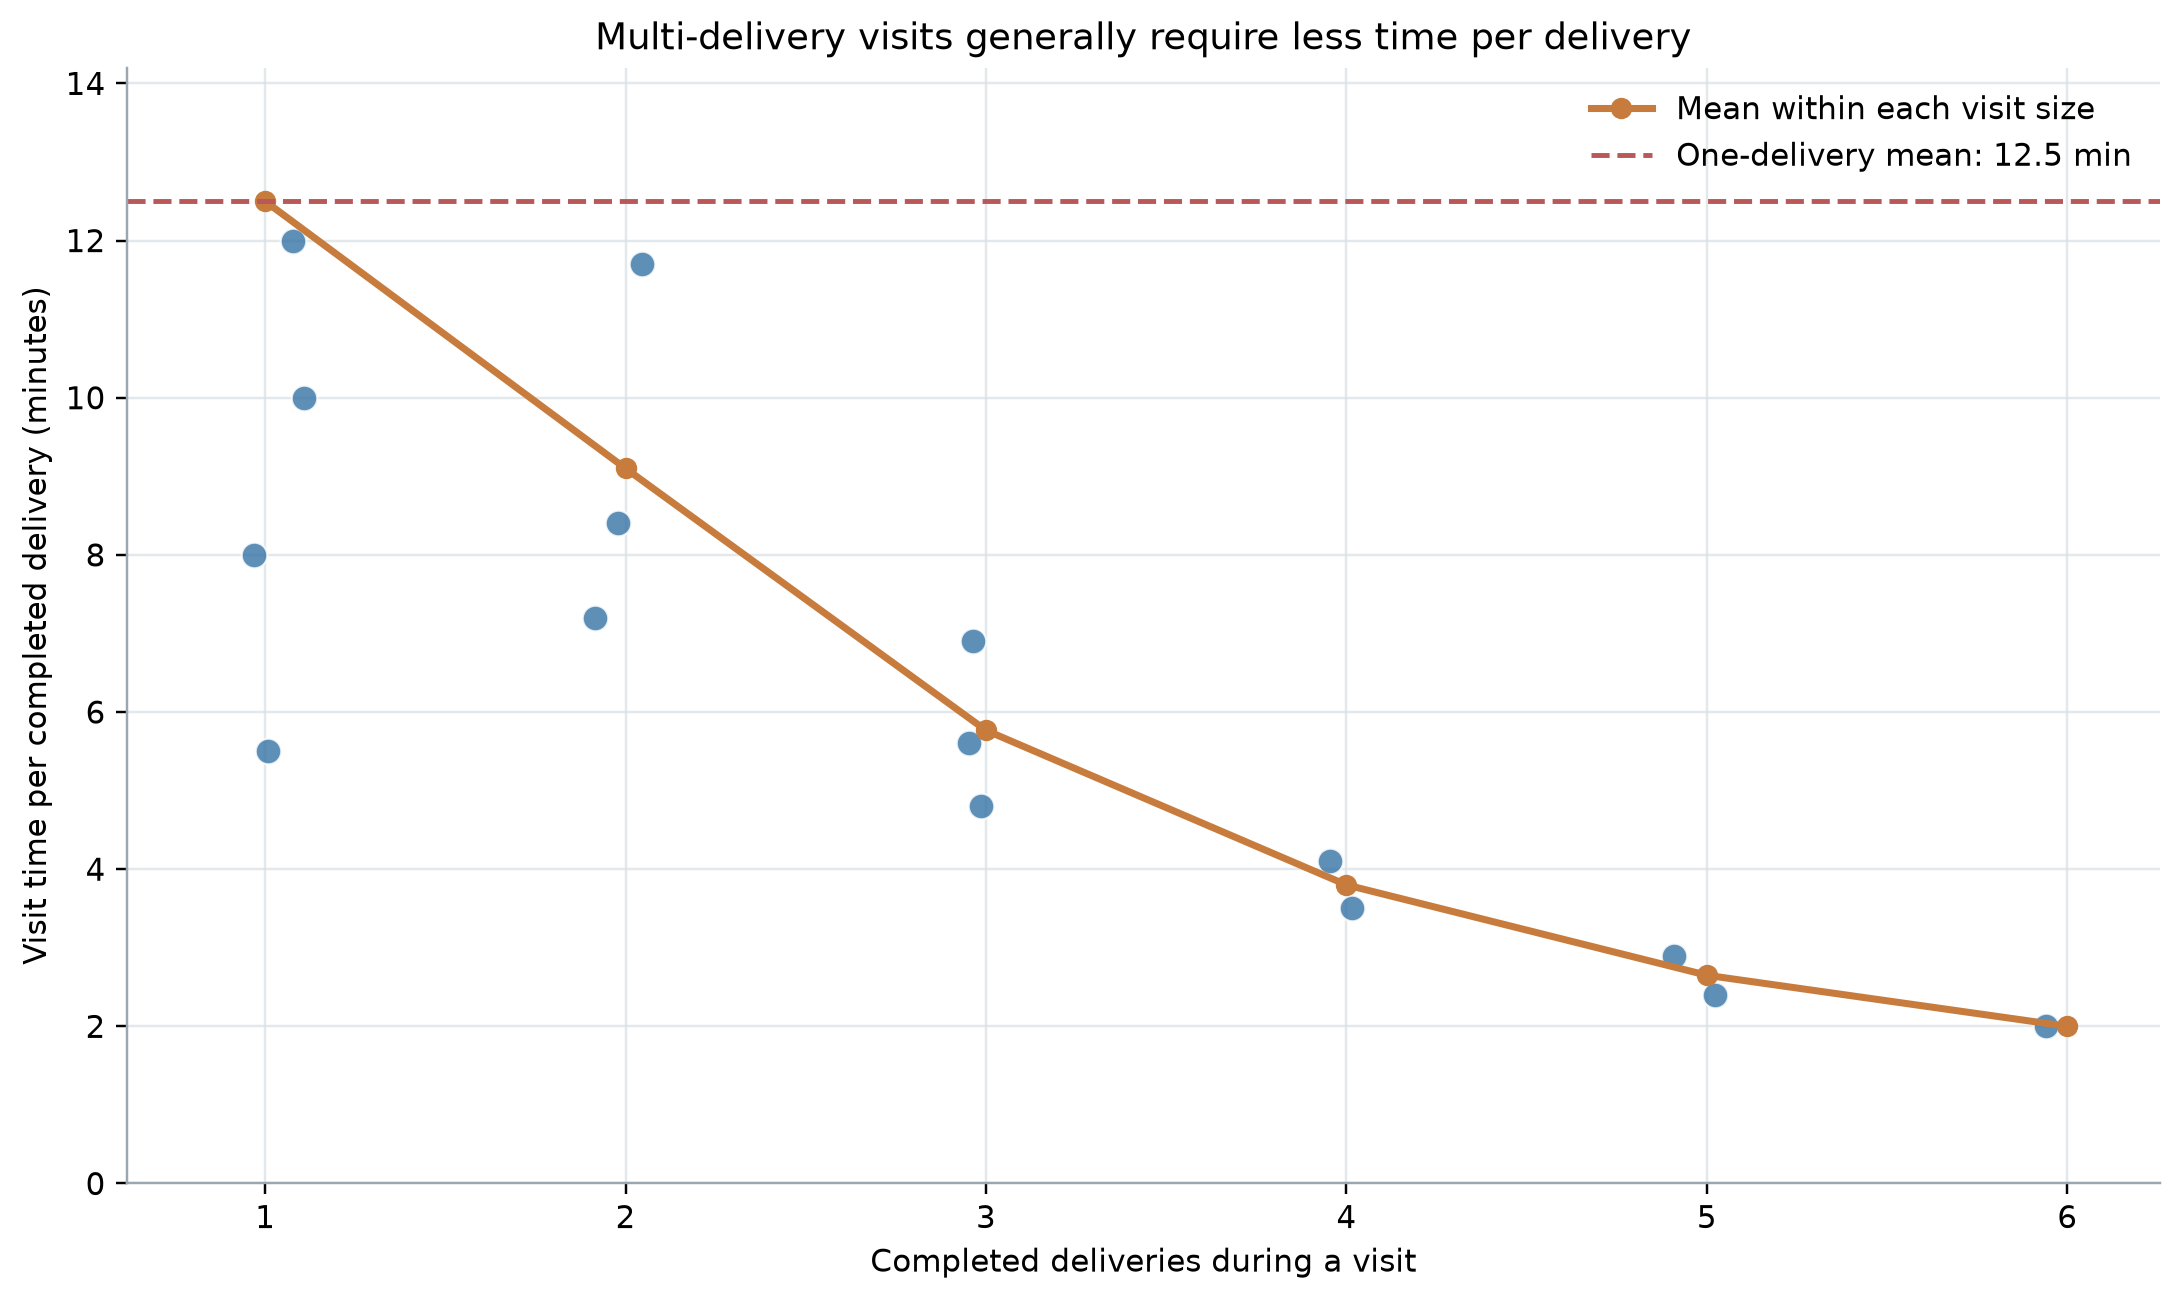

In [ ]:
print(
    df.groupby("completed_deliveries").time_per_delivery_min.agg(
        ["count", "mean", "min", "max"]
    )
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/visit_size_time_per_delivery.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "visit_size_service_time",
  "insight_type": "factor_relationship",
  "insight": "Visits with several completed deliveries generally take less time per delivery than visits with only one.",
  "insight_value": {
    "one_delivery_mean_minutes": 12.5,
    "multi_delivery_time_per_delivery_range_minutes": [
      2.0,
      11.7
    ]
  },
  "plot": {
    "plot_type": "jittered_scatter_with_group_means",
    "title": "Visit Size and Time per Delivery",
    "file": "visualizations/visit_size_time_per_delivery.png",
    "description": "Individual visits retain realistic overlap while visit-size means show the general reduction in time per delivery."
  },
  "question": "How does time per completed delivery vary with the number completed during a visit?",
  "actionable_insight": "Compare the full visit-level distributions and means by completed-delivery count.",
  "code": "print(df.groupby('completed_deliveries').time_per_delivery_min.agg(['count','mean','min','max']))",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_time",
    "gps_position",
    "completed_delivery_count"
  ]
}

### **Question 3**: What distinguishes the longest visit from the other visits?

#### Analysis action

Rank visits by duration and inspect the completed-delivery count of the maximum.

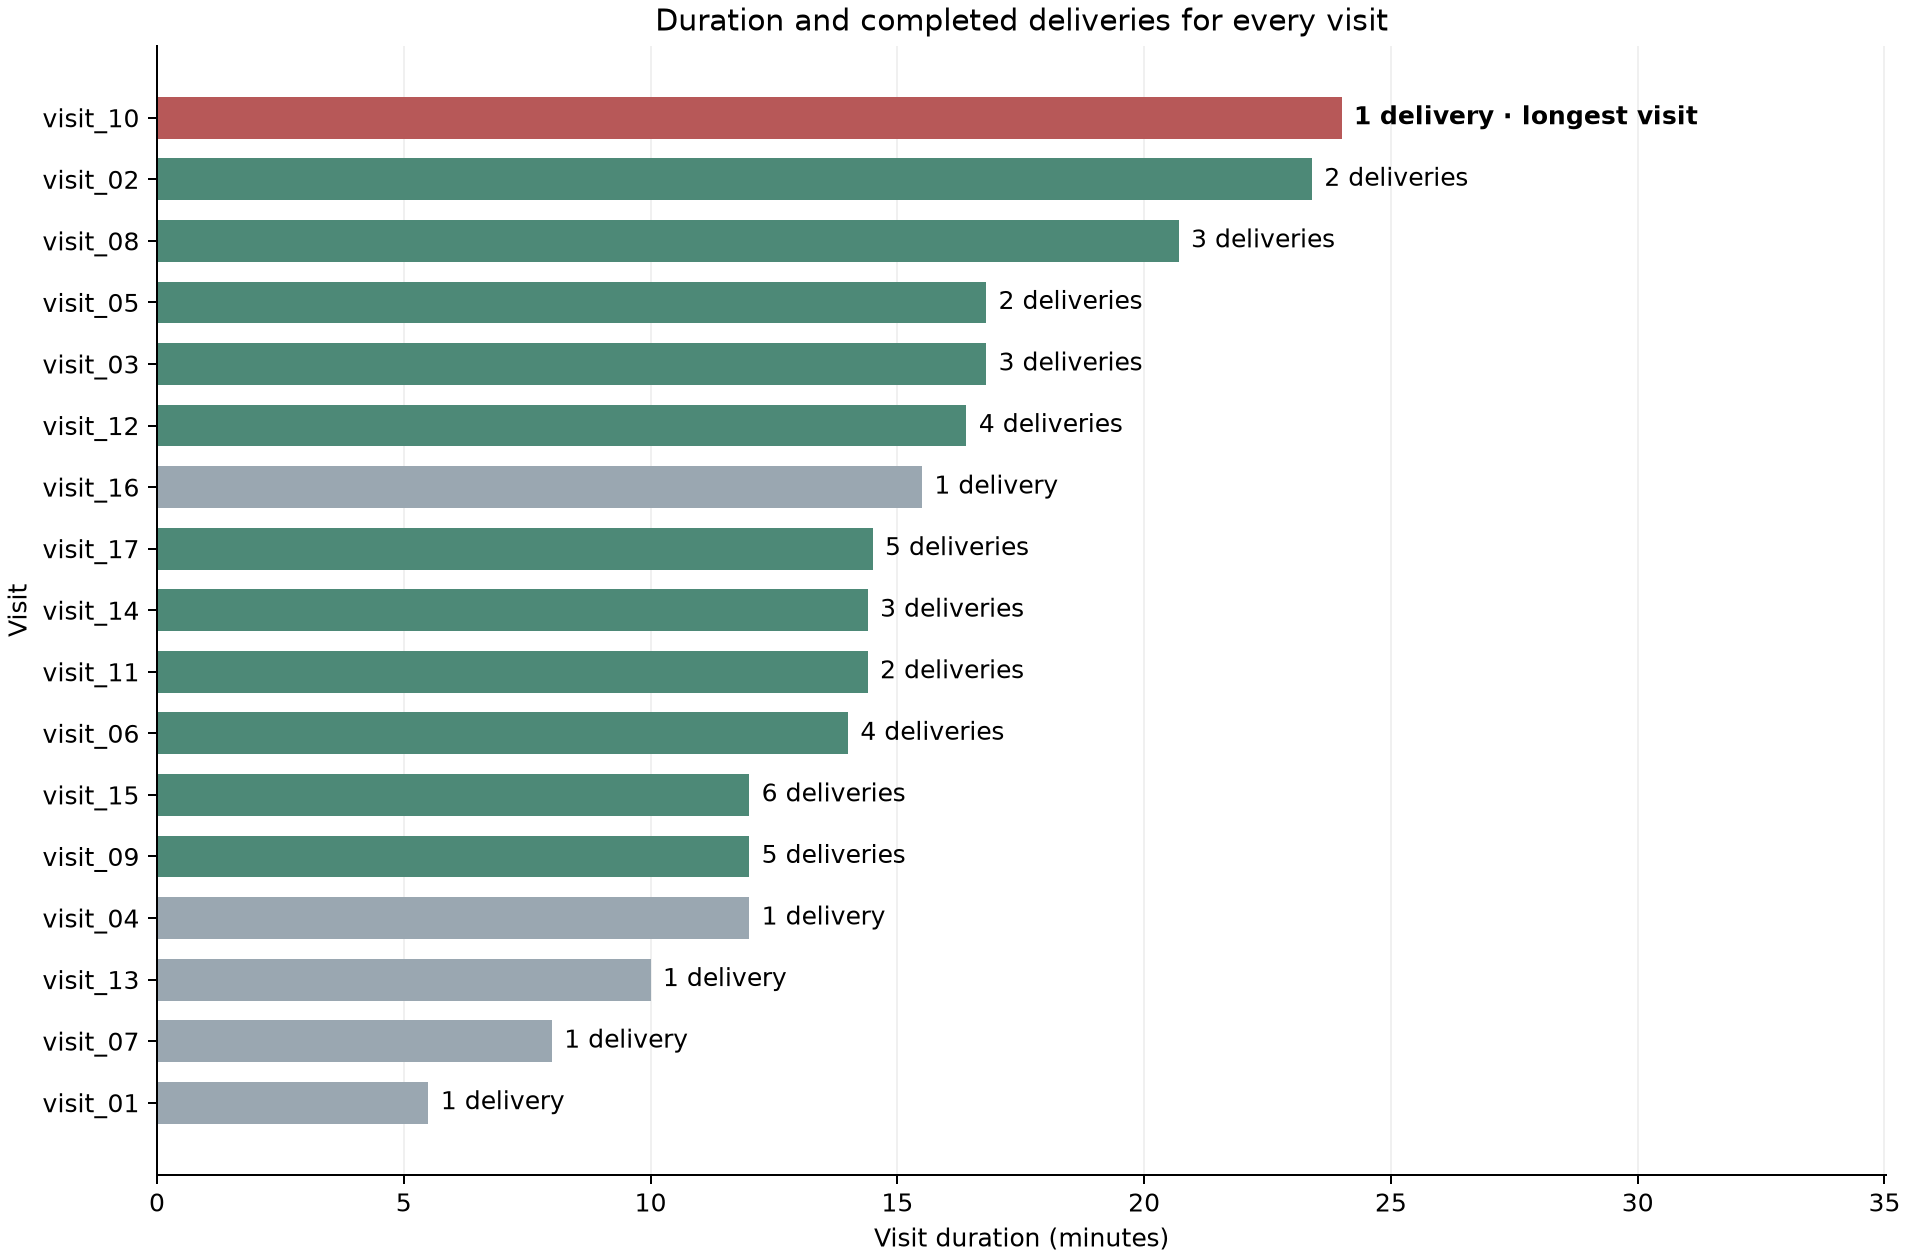

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


def visit_counts(df, user_df):
    ordered = df.sort_values("visit_duration_min")
    longest = ordered.iloc[-1]
    colors = [
        (
            "#b75858"
            if r.visit_id == longest.visit_id
            else "#4d8977" if r.completed_deliveries > 1 else "#9aa7b1"
        )
        for r in ordered.itertuples()
    ]
    fig, ax = plt.subplots(figsize=(10.6, 7.0), constrained_layout=True)
    ax.barh(ordered.visit_id, ordered.visit_duration_min, color=colors, height=0.68)
    for y, row in enumerate(ordered.itertuples()):
        n = int(row.completed_deliveries)
        label = f"{n} {'delivery' if n == 1 else 'deliveries'}"
        if row.visit_id == longest.visit_id:
            label += " · longest visit"
        ax.text(
            row.visit_duration_min + 0.25,
            y,
            label,
            va="center",
            fontsize=10,
            fontweight="bold" if row.visit_id == longest.visit_id else "normal",
        )
    ax.set(
        xlim=(0, longest.visit_duration_min * 1.46),
        xlabel="Visit duration (minutes)",
        ylabel="Visit",
        title="Duration and completed deliveries for every visit",
    )
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.18)
    ax.spines[["top", "right"]].set_visible(False)
    return {
        "longest_visit_id": str(longest.visit_id),
        "duration_minutes": float(longest.visit_duration_min),
        "completed_deliveries": int(longest.completed_deliveries),
    }


evidence = visit_counts(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/visit_duration_exception.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "visit_duration_exception",
  "insight_type": "exception_deviation",
  "insight": "The longest visit includes only one completed delivery.",
  "insight_value": {
    "longest_visit_id": "visit_10",
    "duration_minutes": 24.0,
    "completed_deliveries": 1
  },
  "plot": {
    "plot_type": "ranked_visit_duration_bars",
    "title": "Longest Visit Exception",
    "file": "visualizations/visit_duration_exception.png",
    "description": "All visit durations are ranked, each bar explicitly labels its completed-delivery count, and the longest visit is highlighted."
  },
  "question": "What distinguishes the longest visit from the other visits?",
  "actionable_insight": "Rank visits by duration and inspect the completed-delivery count of the maximum.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\ndef visit_counts(df, user_df):\n    ordered = df.sort_values('visit_duration_min')\n    longest = ordered.iloc[-1]\n    colors = ['#b75858' if r.visit_id == longest.visit_id else '#4d8977'\n        if r.completed_deliveries > 1 else '#9aa7b1' for r in ordered.itertuples()]\n    fig, ax = plt.subplots(figsize=(10.6, 7.0), constrained_layout=True)\n    ax.barh(ordered.visit_id, ordered.visit_duration_min, color=colors, height=.68)\n    for y, row in enumerate(ordered.itertuples()):\n        n = int(row.completed_deliveries)\n        label = f\"{n} {'delivery' if n == 1 else 'deliveries'}\"\n        if row.visit_id == longest.visit_id: label += ' · longest visit'\n        ax.text(row.visit_duration_min+.25, y, label, va='center', fontsize=10,\n            fontweight='bold' if row.visit_id == longest.visit_id else 'normal')\n    ax.set(xlim=(0, longest.visit_duration_min*1.46), xlabel='Visit duration (minutes)',\n        ylabel='Visit', title='Duration and completed deliveries for every visit')\n    ax.set_axisbelow(True); ax.grid(axis='x', alpha=.18)\n    ax.spines[['top', 'right']].set_visible(False)\n    return {'longest_visit_id': str(longest.visit_id), 'duration_minutes': float(longest.visit_duration_min),\n        'completed_deliveries': int(longest.completed_deliveries)}\n\nevidence = visit_counts(df, user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_time",
    "gps_position",
    "completed_delivery_count"
  ]
}

### Summary of Findings (Flag 11)

Most observed time is spent near delivery locations. Multi-delivery visits usually use less time per completed delivery, although visit-level variation remains, and the single longest visit contains only one completion.